# Tumor Detection Project
### Classifying Tumors as Malignant (M) or Benign (B) with a Random Forest Classifier

**Course:** Tute Dude Data Science Course  
**Assignment:** Assignment 7 (Module 14) - Tumor Detection Project  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn (Jupyter Notebook)  
**Student Name:** _(add your name here)_

## 1. Project Introduction

Doctors often need to decide whether a tumor is **malignant** (cancerous) or **benign** (not cancerous). Measurements taken from a tumor - such as its radius, texture, perimeter, area and smoothness - can reveal patterns that help separate the two types.

In this project we use a dataset called `Tumor_Detection.csv` that stores these measurements together with a diagnosis label. We will walk through a complete, beginner-friendly Data Science workflow:

1. Load and inspect the data
2. Clean the data
3. Explore it with statistics and charts (EDA)
4. Study how the features are related (correlation)
5. Scale the features with `StandardScaler`
6. Split the data into training and testing sets
7. Train a `RandomForestClassifier`
8. Evaluate the model and explain the results

## 2. Problem Statement

**Goal:** Build a machine learning model that classifies a tumor as

- **M = Malignant**, or
- **B = Benign**

using the tumor characteristics (mean radius, texture, perimeter, etc.) recorded in `Tumor_Detection.csv`.

**What we must do (from the assignment):** clean the data (remove the irrelevant `id` column and any unnamed extra columns, check missing values), perform EDA on the diagnosis labels, calculate and visualise feature correlations with a heatmap, apply standard scaling, split the data into training and testing sets, train a **Random Forest Classifier**, and evaluate its accuracy.

## 3. Importing Libraries

We import only the libraries this project needs:

- `pandas` and `numpy` - data handling and numerical work
- `matplotlib.pyplot` and `seaborn` - visualisation
- `sklearn` - train/test split, `StandardScaler`, `RandomForestClassifier` and evaluation metrics
- `warnings` - to keep the notebook output clean

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

warnings.filterwarnings("ignore")   # hide non-critical warning messages
sns.set_style("whitegrid")          # clean chart style

print("All libraries imported successfully.")
print("pandas version      :", pd.__version__)
print("scikit-learn version:", sklearn.__version__)

All libraries imported successfully.
pandas version      : 3.0.6
scikit-learn version: 1.9.1


**Output explained:** The libraries imported without errors. The version numbers are printed so the results can be reproduced later.

## 4. Loading the Dataset

We load `Tumor_Detection.csv` with `pd.read_csv()`. The file must be in the **same folder as this notebook** (the project folder already contains both files). We then look at the first five rows with `head()` and the last five rows with `tail()`.

In [2]:
DATA_PATH = "Tumor_Detection.csv"   # CSV file placed in the same folder as this notebook

df = pd.read_csv(DATA_PATH)
pd.set_option("display.max_columns", None)   # show every column when printing a DataFrame

print("Dataset loaded successfully from:", DATA_PATH)

Dataset loaded successfully from: Tumor_Detection.csv


In [3]:
# First five rows
df.head()

,id,diagnosis,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_concave_points,mean_symmetry,mean_fractal_dimension,radius_error,texture_error,perimeter_error,area_error,smoothness_error,compactness_error,concavity_error,concave_points_error,symmetry_error,fractal_dimension_error,worst_radius,worst_texture,worst_perimeter,worst_area,worst_smoothness,worst_compactness,worst_concavity,worst_concave_points,worst_symmetry,worst_fractal_dimension,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842303,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,842304,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,842305,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,842306,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [4]:
# Last five rows
df.tail()

,id,diagnosis,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_concave_points,mean_symmetry,mean_fractal_dimension,radius_error,texture_error,perimeter_error,area_error,smoothness_error,compactness_error,concavity_error,concave_points_error,symmetry_error,fractal_dimension_error,worst_radius,worst_texture,worst_perimeter,worst_area,worst_smoothness,worst_compactness,worst_concavity,worst_concave_points,worst_symmetry,worst_fractal_dimension,Unnamed: 32
564,842866,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,1.1760,1.256,7.673,158.70,0.010300,0.02891,0.05198,0.02454,0.01114,0.004239,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,NaN
565,842867,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,0.7655,2.463,5.203,99.04,0.005769,0.02423,0.03950,0.01678,0.01898,0.002498,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,NaN
566,842868,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,0.4564,1.075,3.425,48.55,0.005903,0.03731,0.04730,0.01557,0.01318,0.003892,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,NaN
567,842869,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,0.7260,1.595,5.772,86.22,0.006522,0.06158,0.07117,0.01664,0.02324,0.006185,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,NaN
568,842870,B,7.76,24.54,47.92,181.0,0.05263,0.04362,0.00000,0.00000,0.1587,0.05884,0.3857,1.428,2.548,19.15,0.007189,0.00466,0.00000,0.00000,0.02676,0.002783,9.456,30.37,59.16,268.6,0.08996,0.06444,0.0000,0.0000,0.2871,0.07039,NaN


**Output explained:** Each row is one tumor sample. The columns include an `id`, the `diagnosis` label (M or B), and many numeric measurements. The last column, `Unnamed: 32`, shows `NaN` (empty) values - it is an extra column that we will remove during cleaning.

## 5. Understanding the Dataset

Before changing anything, we inspect the raw data: its dimensions, column names, data types and summary statistics.

In [5]:
# Dataset dimensions
print("Shape of the dataset (rows, columns):", df.shape)
print("Number of rows   :", df.shape[0])
print("Number of columns:", df.shape[1])

Shape of the dataset (rows, columns): (569, 33)
Number of rows   : 569
Number of columns: 33


In [6]:
# Column names
print("Column names:\n")
for position, column_name in enumerate(df.columns):
    print(f"{position:2d}. {column_name}")

Column names:

 0. id
 1. diagnosis
 2. mean_radius
 3. mean_texture
 4. mean_perimeter
 5. mean_area
 6. mean_smoothness
 7. mean_compactness
 8. mean_concavity
 9. mean_concave_points
10. mean_symmetry
11. mean_fractal_dimension
12. radius_error
13. texture_error
14. perimeter_error
15. area_error
16. smoothness_error
17. compactness_error
18. concavity_error
19. concave_points_error
20. symmetry_error
21. fractal_dimension_error
22. worst_radius
23. worst_texture
24. worst_perimeter
25. worst_area
26. worst_smoothness
27. worst_compactness
28. worst_concavity
29. worst_concave_points
30. worst_symmetry
31. worst_fractal_dimension
32. Unnamed: 32


In [7]:
# Data types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   mean_radius              569 non-null    float64
 3   mean_texture             569 non-null    float64
 4   mean_perimeter           569 non-null    float64
 5   mean_area                569 non-null    float64
 6   mean_smoothness          569 non-null    float64
 7   mean_compactness         569 non-null    float64
 8   mean_concavity           569 non-null    float64
 9   mean_concave_points      569 non-null    float64
 10  mean_symmetry            569 non-null    float64
 11  mean_fractal_dimension   569 non-null    float64
 12  radius_error             569 non-null    float64
 13  texture_error            569 non-null    float64
 14  perimeter_error          569 non-null

In [8]:
# Descriptive statistics of the numerical columns
df.describe()

,id,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_concave_points,mean_symmetry,mean_fractal_dimension,radius_error,texture_error,perimeter_error,area_error,smoothness_error,compactness_error,concavity_error,concave_points_error,symmetry_error,fractal_dimension_error,worst_radius,worst_texture,worst_perimeter,worst_area,worst_smoothness,worst_compactness,worst_concavity,worst_concave_points,worst_symmetry,worst_fractal_dimension,Unnamed: 32
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,0.0
mean,842586.000000,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,0.405172,1.216853,2.866059,40.337079,0.007041,0.025478,0.031894,0.011796,0.020542,0.003795,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,164.400426,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,0.277313,0.551648,2.021855,45.491006,0.003003,0.017908,0.030186,0.006170,0.008266,0.002646,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,842302.000000,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,0.111500,0.360200,0.757000,6.802000,0.001713,0.002252,0.000000,0.000000,0.007882,0.000895,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,842444.000000,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,0.232400,0.833900,1.606000,17.850000,0.005169,0.013080,0.015090,0.007638,0.015160,0.002248,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,842586.000000,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,0.324200,1.108000,2.287000,24.530000,0.006380,0.020450,0.025890,0.010930,0.018730,0.003187,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,842728.000000,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,0.478900,1.474000,3.357000,45.190000,0.008146,0.032450,0.042050,0.014710,0.023480,0.004558,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN
max,842870.000000,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,2.873000,4.885000,21.980000,542.200000,0.031130,0.135400,0.396000,0.052790,0.078950,0.029840,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,NaN


In [9]:
# Confirm the target column exists and see which labels it contains
print("'diagnosis' column present:", "diagnosis" in df.columns)
print("Unique diagnosis labels   :", df["diagnosis"].unique())

'diagnosis' column present: True
Unique diagnosis labels   : <StringArray>
['M', 'B']
Length: 2, dtype: str


**Output explained:**

- The dataset has **569 rows** (tumor samples) and **33 columns**.
- `info()` shows that `id` is an integer, `diagnosis` is text (M / B), and the measurement columns are decimal numbers. The `Unnamed: 32` column has **zero** non-null values, which confirms it is an empty, useless column.
- `describe()` shows that features are on very different scales - for example `mean_area` has values in the hundreds or thousands while `mean_smoothness` is a small decimal. This is why **standard scaling** is a useful preprocessing step.
- The target column `diagnosis` exists and contains only the labels **M** and **B**.

## 6. Data Cleaning

The assignment asks us to:

1. Remove the irrelevant `id` column (an identifier carries no medical meaning for prediction).
2. Remove unnamed extra columns.
3. Check for missing values with `isnull().sum()` and handle them if present.
4. Check for duplicate records.
5. Display the cleaned dataset.

We must be careful **not** to remove the `diagnosis` target column or any useful feature.

In [10]:
# Step 1: identify the irrelevant columns by looking at the actual column names
id_columns = [col for col in df.columns if col.strip().lower() == "id"]
unnamed_columns = [col for col in df.columns if col.strip().lower().startswith("unnamed")]

print("ID column(s) found      :", id_columns)
print("Unnamed column(s) found :", unnamed_columns)

ID column(s) found      : ['id']
Unnamed column(s) found : ['Unnamed: 32']


In [11]:
# Step 2: missing values in the ORIGINAL dataset
df.isnull().sum()

id                           0
diagnosis                    0
mean_radius                  0
mean_texture                 0
mean_perimeter               0
mean_area                    0
mean_smoothness              0
mean_compactness             0
mean_concavity               0
mean_concave_points          0
mean_symmetry                0
mean_fractal_dimension       0
radius_error                 0
texture_error                0
perimeter_error              0
area_error                   0
smoothness_error             0
compactness_error            0
concavity_error              0
concave_points_error         0
symmetry_error               0
fractal_dimension_error      0
worst_radius                 0
worst_texture                0
worst_perimeter              0
worst_area                   0
worst_smoothness             0
worst_compactness            0
worst_concavity              0
worst_concave_points         0
worst_symmetry               0
worst_fractal_dimension      0
Unnamed:

**Output explained:** Only the `Unnamed: 32` column has missing values - all 569 of its entries are empty. Every real measurement column and the `diagnosis` column are complete.

In [12]:
# Step 3: remove the 'id' and unnamed columns (the 'diagnosis' target is NOT touched)
df_clean = df.drop(columns=id_columns + unnamed_columns)

print("Columns removed:", id_columns + unnamed_columns)
print("Shape before cleaning:", df.shape)
print("Shape after removing irrelevant columns:", df_clean.shape)
print("'diagnosis' column still present:", "diagnosis" in df_clean.columns)

Columns removed: ['id', 'Unnamed: 32']
Shape before cleaning: (569, 33)
Shape after removing irrelevant columns: (569, 31)
'diagnosis' column still present: True


In [13]:
# Step 4: check for missing values again in the cleaned data and handle them if present
df_clean = df_clean.dropna(subset=["diagnosis"])   # a row without a label cannot be used

total_missing = df_clean.isnull().sum().sum()
print("Total missing values after removing unnamed columns:", total_missing)

if total_missing > 0:
    # Fill missing numeric values with the median of each column
    numeric_columns = df_clean.select_dtypes(include=np.number).columns
    df_clean[numeric_columns] = df_clean[numeric_columns].fillna(df_clean[numeric_columns].median())
    print("Missing values were filled with column medians.")
    print("Missing values now:", df_clean.isnull().sum().sum())
else:
    print("No missing values remain, so no imputation is required.")

Total missing values after removing unnamed columns: 0
No missing values remain, so no imputation is required.


In [14]:
# Step 5: check for duplicate records (done after dropping 'id', because 'id' is unique for every row)
duplicate_count = df_clean.duplicated().sum()
print("Number of duplicate rows:", duplicate_count)

if duplicate_count > 0:
    df_clean = df_clean.drop_duplicates().reset_index(drop=True)
    print("Duplicate rows removed. New shape:", df_clean.shape)
else:
    print("No duplicate records found, so nothing needs to be removed.")

Number of duplicate rows: 0
No duplicate records found, so nothing needs to be removed.


In [15]:
# Step 6: display the dataset after cleaning
print("Cleaned dataset shape:", df_clean.shape)
df_clean.head()

Cleaned dataset shape: (569, 31)


,diagnosis,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_concave_points,mean_symmetry,mean_fractal_dimension,radius_error,texture_error,perimeter_error,area_error,smoothness_error,compactness_error,concavity_error,concave_points_error,symmetry_error,fractal_dimension_error,worst_radius,worst_texture,worst_perimeter,worst_area,worst_smoothness,worst_compactness,worst_concavity,worst_concave_points,worst_symmetry,worst_fractal_dimension
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


**Output explained:** After cleaning, the dataset has **569 rows and 31 columns** - the `diagnosis` target plus **30 numeric feature columns**. There are no missing values and no duplicate rows were found. The `id` and `Unnamed: 32` columns are gone, and no useful column was lost.

## 7. Exploratory Data Analysis (EDA)

EDA helps us understand the data before building a model. We will look at:

1. How many malignant and benign cases there are
2. Descriptive statistics of all numerical features
3. How feature values differ between malignant and benign tumors
4. The shape of the distributions (histograms) and spread (box plots)

In [16]:
# 1. Distribution of malignant and benign cases
diagnosis_counts = df_clean["diagnosis"].value_counts()
diagnosis_percent = df_clean["diagnosis"].value_counts(normalize=True) * 100

distribution = pd.DataFrame({
    "Count": diagnosis_counts,
    "Percentage (%)": diagnosis_percent.round(2)
})
distribution.index = distribution.index.map({"B": "B (Benign)", "M": "M (Malignant)"})
distribution

,Count,Percentage (%)
diagnosis,,
B (Benign),357,62.74
M (Malignant),212,37.26


In [17]:
# 2. Descriptive statistics of the cleaned numerical features (transposed so each feature is one row)
df_clean.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
mean_radius,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
mean_texture,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
mean_perimeter,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
mean_area,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
mean_smoothness,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
mean_compactness,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
mean_concavity,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
mean_concave_points,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
mean_symmetry,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
mean_fractal_dimension,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097


In [18]:
# 3. Numerical feature analysis: average of each 'mean_' feature for benign vs malignant tumors
mean_features = [col for col in df_clean.columns if col.startswith("mean_")]

group_means = df_clean.groupby("diagnosis")[mean_features].mean().T
group_means["M_to_B_ratio"] = (group_means["M"] / group_means["B"]).round(2)
group_means.round(3)

diagnosis,B,M,M_to_B_ratio
mean_radius,12.147,17.463,1.44
mean_texture,17.915,21.605,1.21
mean_perimeter,78.075,115.365,1.48
mean_area,462.790,978.376,2.11
mean_smoothness,0.092,0.103,1.11
mean_compactness,0.080,0.145,1.81
mean_concavity,0.046,0.161,3.49
mean_concave_points,0.026,0.088,3.42
mean_symmetry,0.174,0.193,1.11
mean_fractal_dimension,0.063,0.063,1.00


**Output explained:**

- **Class distribution:** There are **357 benign (62.74%)** and **212 malignant (37.26%)** cases. Benign cases are more common, but the classes are reasonably balanced - not a severely imbalanced dataset.
- **Group averages:** The last column shows how many times larger the malignant average is than the benign average. For example, the malignant average of `mean_radius` is about **1.44x** the benign average, `mean_area` about **2.11x** and `mean_concave_points` about **3.42x**. By contrast `mean_fractal_dimension` has a ratio of about **1.0x**, so it barely differs between the two groups.

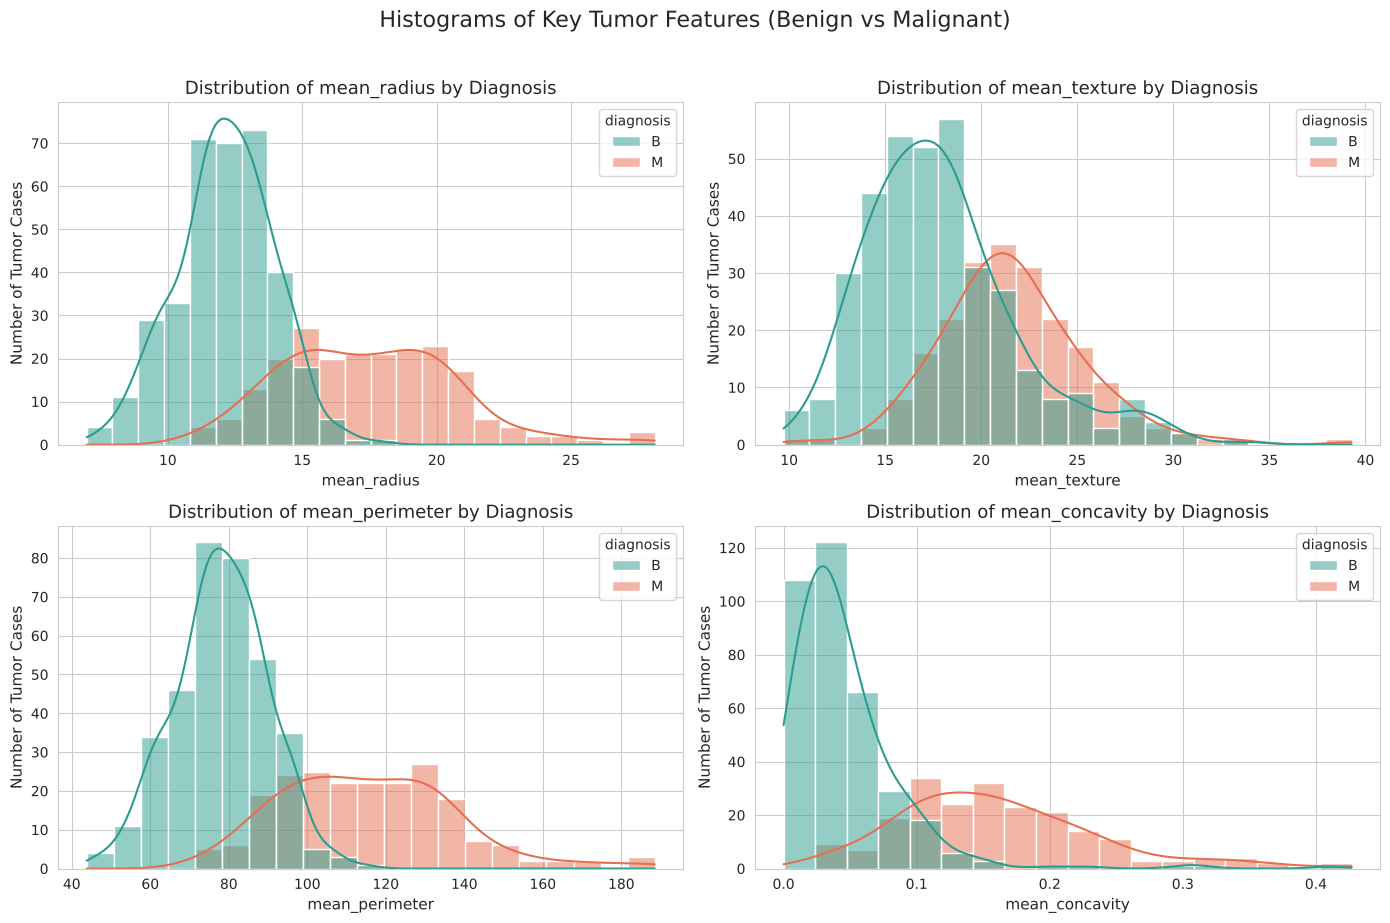

In [19]:
# 4. Histograms: how do key features differ between benign and malignant tumors?
palette = {"B": "#2a9d8f", "M": "#e76f51"}   # green = benign, orange-red = malignant
hist_features = ["mean_radius", "mean_texture", "mean_perimeter", "mean_concavity"]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, feature in zip(axes.ravel(), hist_features):
    sns.histplot(data=df_clean, x=feature, hue="diagnosis", kde=True,
                 palette=palette, hue_order=["B", "M"], ax=ax)
    ax.set_title(f"Distribution of {feature} by Diagnosis", fontsize=13)
    ax.set_xlabel(feature, fontsize=11)
    ax.set_ylabel("Number of Tumor Cases", fontsize=11)

plt.suptitle("Histograms of Key Tumor Features (Benign vs Malignant)", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

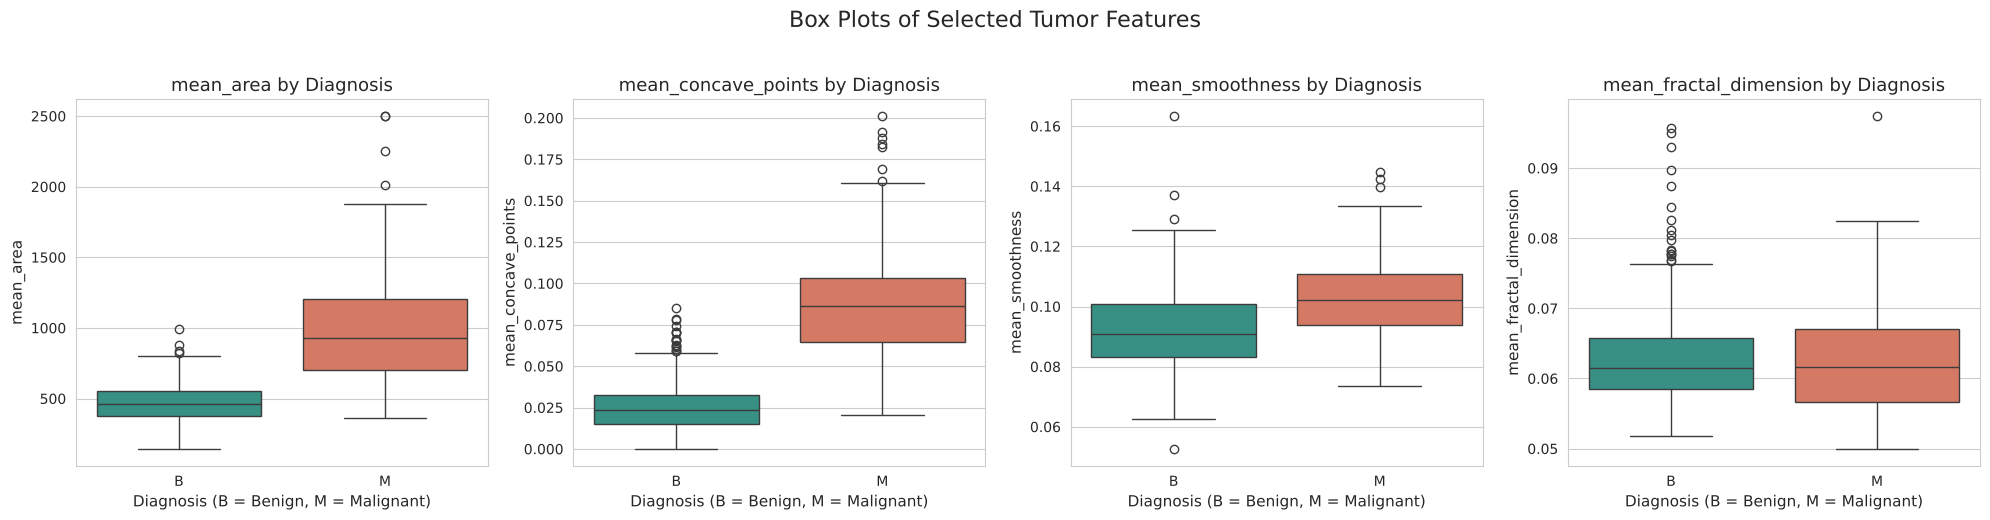

In [20]:
# 5. Box plots: compare the spread of selected features for each diagnosis
box_features = ["mean_area", "mean_concave_points", "mean_smoothness", "mean_fractal_dimension"]

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, feature in zip(axes, box_features):
    sns.boxplot(data=df_clean, x="diagnosis", y=feature, hue="diagnosis",
                order=["B", "M"], hue_order=["B", "M"], palette=palette, legend=False, ax=ax)
    ax.set_title(f"{feature} by Diagnosis", fontsize=13)
    ax.set_xlabel("Diagnosis (B = Benign, M = Malignant)", fontsize=11)
    ax.set_ylabel(feature, fontsize=11)

plt.suptitle("Box Plots of Selected Tumor Features", fontsize=16, y=1.03)
plt.tight_layout()
plt.show()

**Output explained:**

- In the **histograms**, the orange (malignant) curves for `mean_radius`, `mean_perimeter` and `mean_concavity` sit clearly to the right of the green (benign) curves, meaning malignant tumors tend to have larger values. `mean_texture` shows the same direction but with much more overlap.
- In the **box plots**, `mean_area` and `mean_concave_points` show a clear separation between the two groups, while `mean_fractal_dimension` overlaps almost completely - so it is a weak feature for telling the groups apart.
- Both groups contain some outlier values (the dots beyond the whiskers), which is common in medical measurement data. We keep these values because they are real measurements, not errors.

## 8. Diagnosis Distribution Visualization

A **count plot** shows how many samples belong to each diagnosis class. This is the main visual check of class balance.

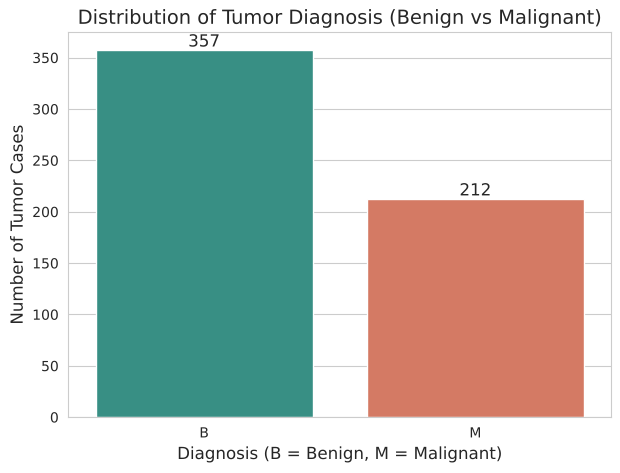

In [21]:
plt.figure(figsize=(7, 5))
ax = sns.countplot(data=df_clean, x="diagnosis", hue="diagnosis", order=["B", "M"],
                   hue_order=["B", "M"], palette=palette, legend=False)

for container in ax.containers:
    ax.bar_label(container, fontsize=12)   # write the count on top of each bar

plt.title("Distribution of Tumor Diagnosis (Benign vs Malignant)", fontsize=14)
plt.xlabel("Diagnosis (B = Benign, M = Malignant)", fontsize=12)
plt.ylabel("Number of Tumor Cases", fontsize=12)
plt.show()

**Output explained:** The count plot confirms **357 benign** and **212 malignant** tumors. Because both classes have plenty of examples, the model has enough malignant cases to learn from.

## 9. Correlation Matrix and Heatmap

Correlation measures how strongly two numerical features move together. It ranges from **-1** to **+1**:

- close to **+1** -> when one feature increases, the other increases too
- close to **0** -> little or no linear relationship
- close to **-1** -> when one feature increases, the other decreases

Only **numeric** columns are used. The text column `diagnosis` is excluded from this calculation automatically.

In [22]:
# Select numeric columns only (the text 'diagnosis' column is excluded)
numeric_df = df_clean.select_dtypes(include=np.number)

print("Numeric columns used for correlation:", numeric_df.shape[1])
print("Non-numeric columns excluded       :", [c for c in df_clean.columns if c not in numeric_df.columns])

# Correlation matrix
corr_matrix = numeric_df.corr()
print("Correlation matrix shape:", corr_matrix.shape)

Numeric columns used for correlation: 30
Non-numeric columns excluded       : ['diagnosis']
Correlation matrix shape: (30, 30)


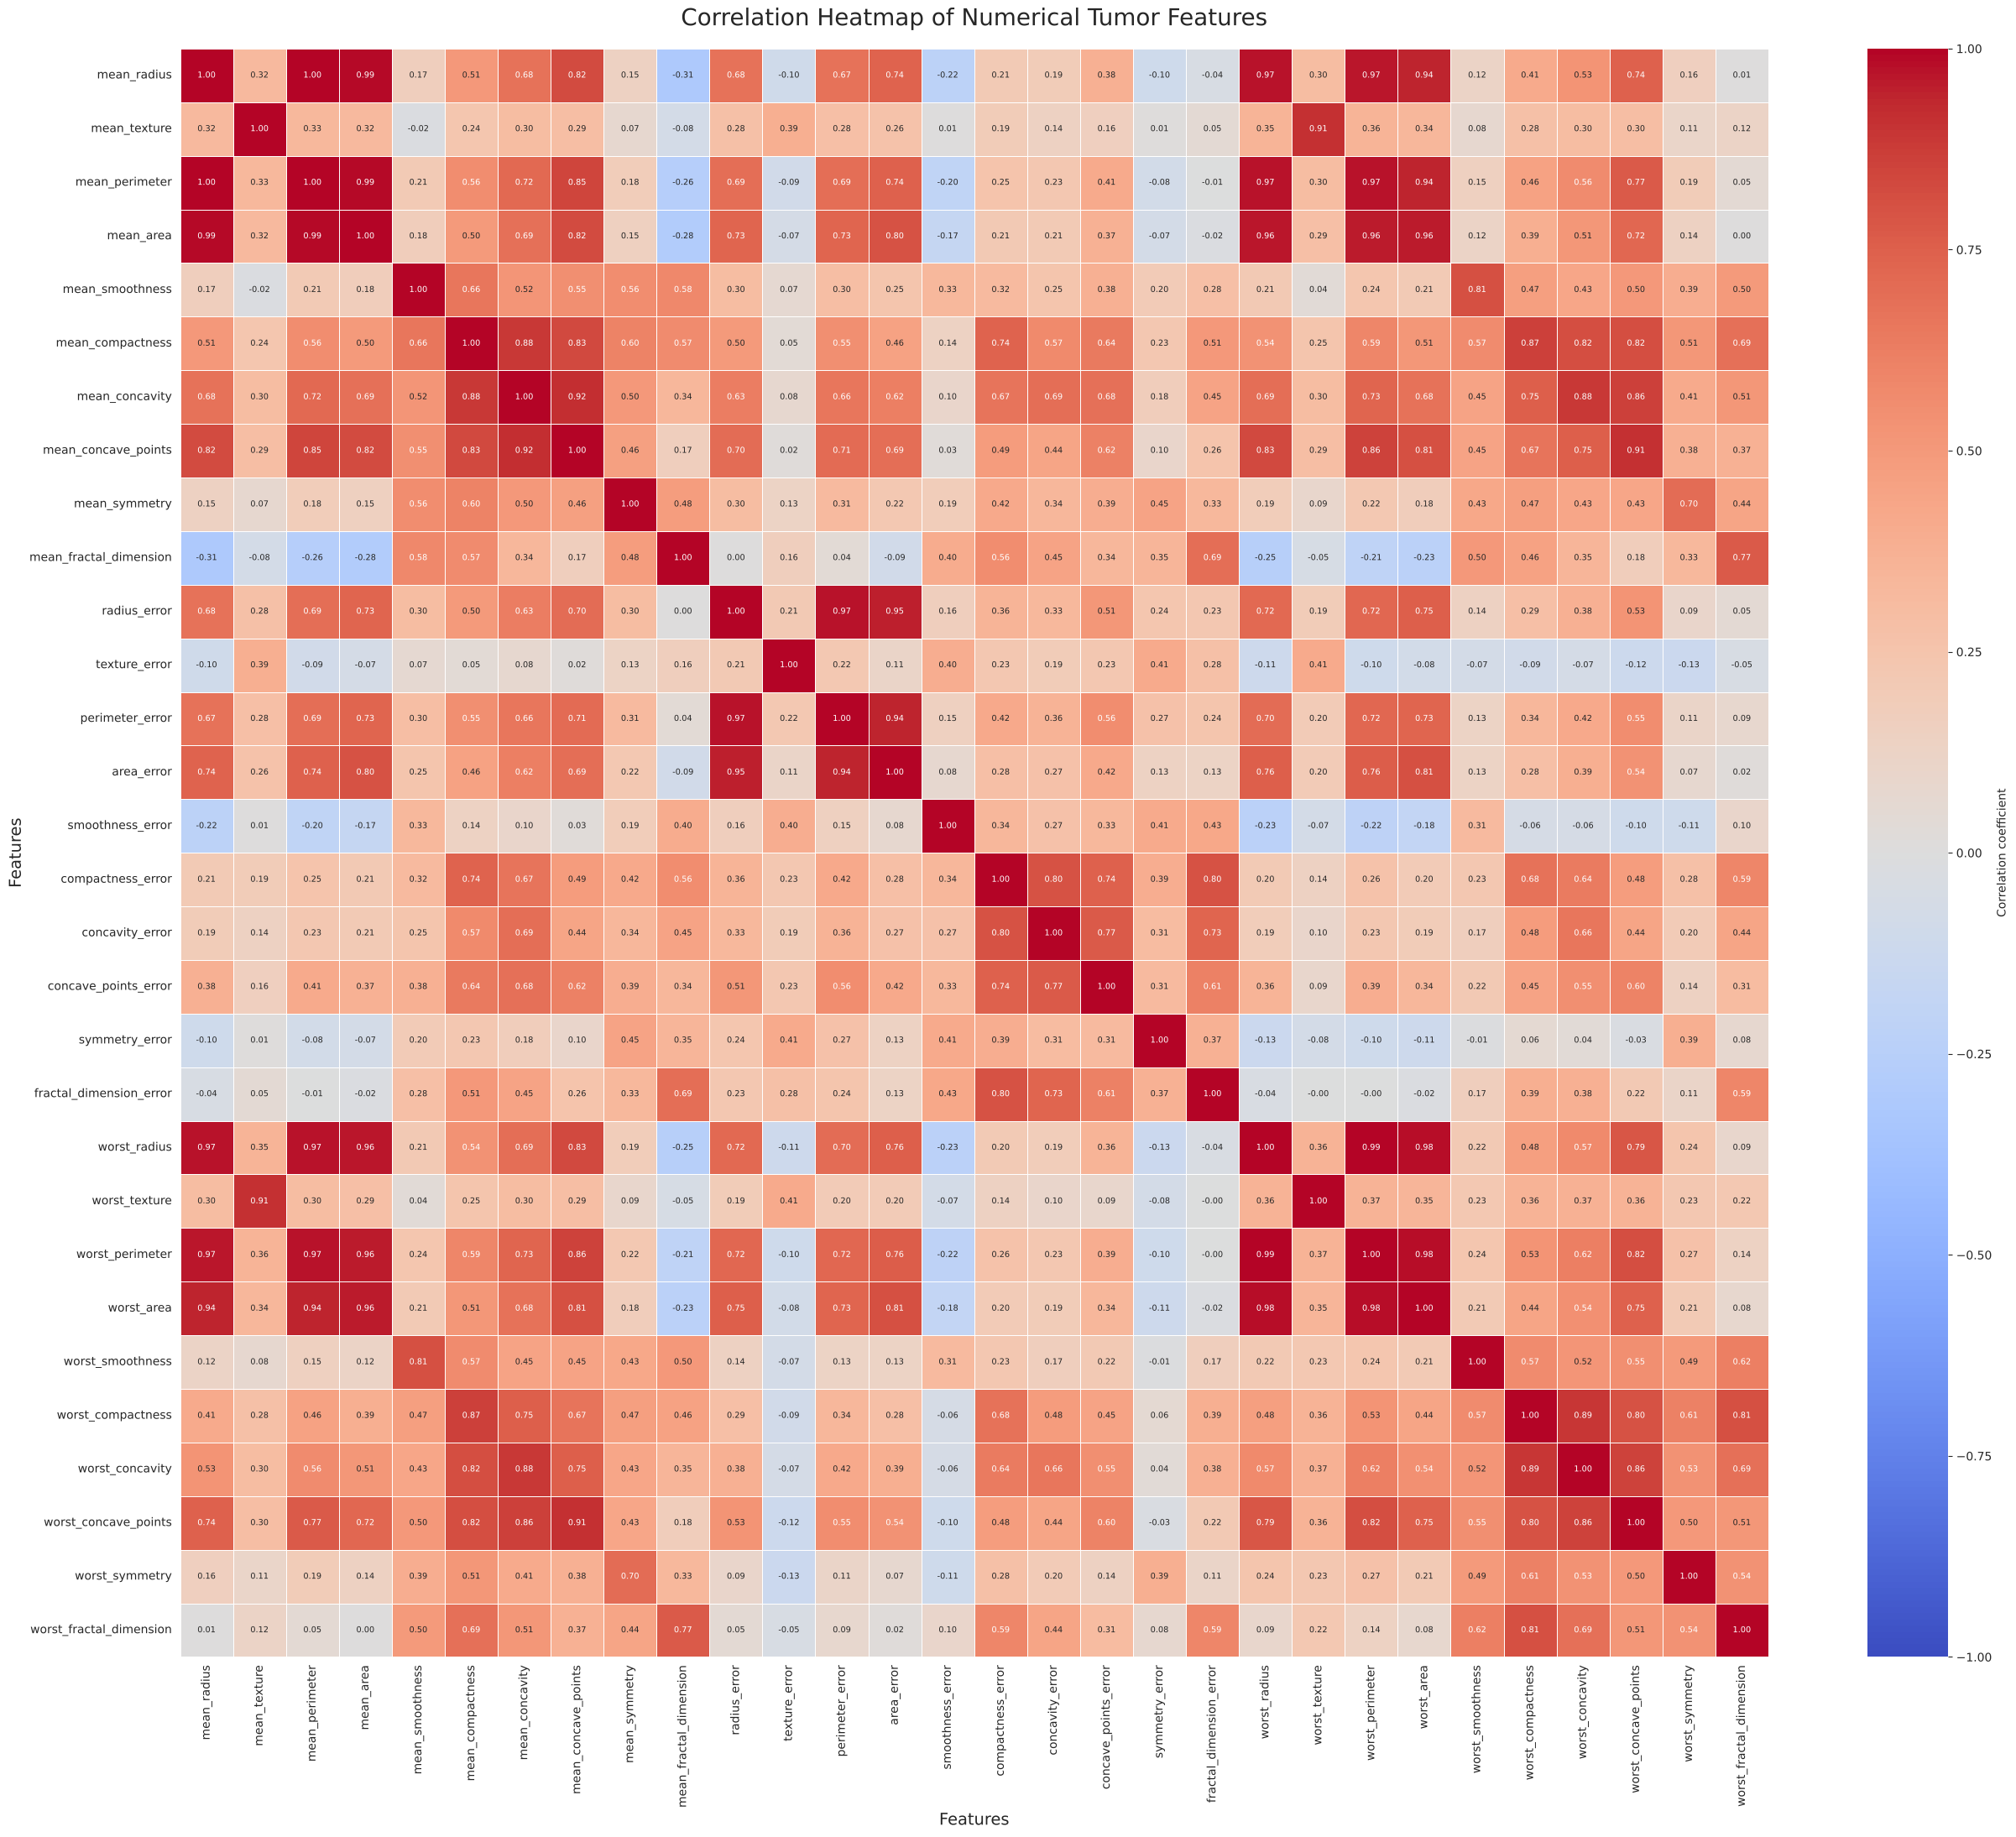

In [23]:
# Heatmap of the correlation matrix (large figure so every value is readable)
plt.figure(figsize=(26, 22))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            linewidths=0.4, annot_kws={"size": 7},
            cbar_kws={"label": "Correlation coefficient"})

plt.title("Correlation Heatmap of Numerical Tumor Features", fontsize=20, pad=20)
plt.xlabel("Features", fontsize=14)
plt.ylabel("Features", fontsize=14)
plt.xticks(rotation=90, fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()
plt.show()

In [24]:
# The 10 most strongly correlated pairs of features
upper_triangle = corr_matrix.where(np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1))
top_pairs = upper_triangle.stack().sort_values(ascending=False).head(10).reset_index()
top_pairs.columns = ["Feature 1", "Feature 2", "Correlation"]
top_pairs["Correlation"] = top_pairs["Correlation"].round(3)
top_pairs

,Feature 1,Feature 2,Correlation
0,mean_radius,mean_perimeter,0.998
1,worst_radius,worst_perimeter,0.994
2,mean_radius,mean_area,0.987
3,mean_perimeter,mean_area,0.987
4,worst_radius,worst_area,0.984
5,worst_perimeter,worst_area,0.978
6,radius_error,perimeter_error,0.973
7,mean_perimeter,worst_perimeter,0.970
8,mean_radius,worst_radius,0.970
9,mean_perimeter,worst_radius,0.969


In [25]:
# Correlation of each feature with the diagnosis (M = 1, B = 0 used here only for this calculation)
diagnosis_numeric = df_clean["diagnosis"].map({"M": 1, "B": 0})
corr_with_diagnosis = numeric_df.corrwith(diagnosis_numeric).sort_values(ascending=False)

print("Top 10 features most positively correlated with malignancy:\n")
print(corr_with_diagnosis.head(10).round(3))
print("\nFive features with the weakest relationship to the diagnosis (smallest absolute correlation):\n")
print(corr_with_diagnosis.abs().sort_values().head(5).round(3))

Top 10 features most positively correlated with malignancy:

worst_concave_points    0.794
worst_perimeter         0.783
mean_concave_points     0.777
worst_radius            0.776
mean_perimeter          0.743
worst_area              0.734
mean_radius             0.730
mean_area               0.709
mean_concavity          0.696
worst_concavity         0.660
dtype: float64

Five features with the weakest relationship to the diagnosis (smallest absolute correlation):

symmetry_error             0.007
texture_error              0.008
mean_fractal_dimension     0.013
smoothness_error           0.067
fractal_dimension_error    0.078
dtype: float64


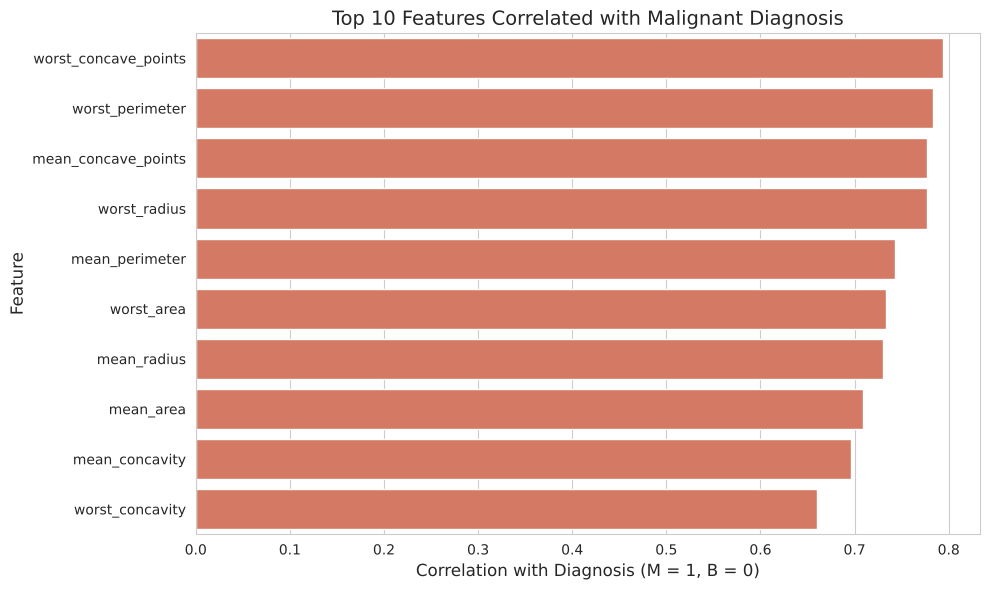

In [26]:
# Visualise the 10 strongest correlations with the diagnosis
top_corr = corr_with_diagnosis.head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_corr.values, y=top_corr.index, color="#e76f51")
plt.title("Top 10 Features Correlated with Malignant Diagnosis", fontsize=14)
plt.xlabel("Correlation with Diagnosis (M = 1, B = 0)", fontsize=12)
plt.ylabel("Feature", fontsize=12)
plt.tight_layout()
plt.show()

**Important correlations explained:**

- **Size features move together almost perfectly.** `mean_radius` and `mean_perimeter` have a correlation of **0.998**, and `mean_radius` and `mean_area` have **0.987**. This makes sense: a tumor with a bigger radius naturally has a bigger perimeter and area.
- **Shape features are linked too.** `mean_concavity` and `mean_concave_points` have a correlation of **0.921**.
- **"Mean" and "worst" versions agree.** `mean_radius` and `worst_radius` have a correlation of **0.970**, so they carry very similar information.
- **Features most related to malignancy:** the strongest correlation with the diagnosis is `worst_concave_points` (**0.794**), followed by `worst_perimeter` (**0.783**) and `mean_concave_points` (**0.777**). Size and concavity-related features dominate this list.
- **Weakest features:** `symmetry_error` (**-0.007**) and `texture_error` (**-0.008**) have almost no linear relationship with the diagnosis.

Many features are strongly correlated with each other (called *multicollinearity*). Random Forest handles this well, so we keep all features.

## 10. Feature Selection

We now define:

- **`y`** - the target variable (`diagnosis`), converted to numbers: **M = 1** (malignant) and **B = 0** (benign)
- **`X`** - the independent features (every column except `diagnosis`)

The target must never be placed inside `X`, otherwise the model would simply "see" the answer.

In [27]:
# Convert diagnosis labels to numbers
label_mapping = {"M": 1, "B": 0}
y = df_clean["diagnosis"].map(label_mapping)

# Independent features: everything except the target column
X = df_clean.drop(columns=["diagnosis"])

print("Label mapping used:", label_mapping)
print("X shape (samples, features):", X.shape)
print("y shape (samples,)         :", y.shape)

Label mapping used: {'M': 1, 'B': 0}
X shape (samples, features): (569, 30)
y shape (samples,)         : (569,)


In [28]:
# Verify the label mapping: each original label must map to exactly one number
pd.crosstab(df_clean["diagnosis"], y, rownames=["Original label"], colnames=["Encoded value"])

Encoded value,0,1
Original label,,
B,357,0
M,0,212


In [29]:
# Safety checks
assert "diagnosis" not in X.columns, "The target column must not be inside X"
assert y.isnull().sum() == 0, "Some labels were not mapped"
assert set(y.unique()) == {0, 1}, "y should contain only 0 and 1"
assert all(pd.api.types.is_numeric_dtype(dtype) for dtype in X.dtypes), "All features must be numeric"

print("All checks passed.")
print("Number of features in X:", X.shape[1])
print("Feature names:", X.columns.tolist())

All checks passed.
Number of features in X: 30
Feature names: ['mean_radius', 'mean_texture', 'mean_perimeter', 'mean_area', 'mean_smoothness', 'mean_compactness', 'mean_concavity', 'mean_concave_points', 'mean_symmetry', 'mean_fractal_dimension', 'radius_error', 'texture_error', 'perimeter_error', 'area_error', 'smoothness_error', 'compactness_error', 'concavity_error', 'concave_points_error', 'symmetry_error', 'fractal_dimension_error', 'worst_radius', 'worst_texture', 'worst_perimeter', 'worst_area', 'worst_smoothness', 'worst_compactness', 'worst_concavity', 'worst_concave_points', 'worst_symmetry', 'worst_fractal_dimension']


**Output explained:** The cross-tabulation proves the mapping is correct - every **B** became **0** and every **M** became **1**, with nothing left unmapped. `X` contains **30 numeric features** and does **not** contain `diagnosis`.

## 11. Data Preprocessing and Standard Scaling

`StandardScaler` rescales each feature so that it has a **mean of 0** and a **standard deviation of 1**: 

$$z = \frac{x - \mu}{\sigma}$$

Random Forest does not strictly need scaled data, but the assignment explicitly requires `StandardScaler`, so we include it.

**Avoiding data leakage - the correct order matters:**

1. **Split first** into training and testing sets (next section).
2. **Fit** the scaler on the **training data only** (it learns the mean and standard deviation from the training set).
3. **Transform** both the training and the testing data using that already-fitted scaler.

If we scaled before splitting, or fitted the scaler on the test data, information from the test set would "leak" into training and the accuracy would not be trustworthy.  
In this section we only **create** the scaler object. It is fitted in the next section, immediately after the split.

In [30]:
# Create the scaler (NOT fitted yet - it will be fitted on the training data only)
scaler = StandardScaler()
print(scaler)

StandardScaler()


## 12. Train-Test Split

We split the data into **80% training** and **20% testing** using `train_test_split()` with:

- `test_size = 0.2`
- `random_state = 42` (makes the split reproducible)
- `stratify = y` (keeps the same benign/malignant proportion in both sets)

In [31]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape :", y_test.shape)

X_train shape: (455, 30)
X_test shape : (114, 30)
y_train shape: (455,)
y_test shape : (114,)


In [32]:
# Check that the class proportions are preserved in both sets (stratification)
split_summary = pd.DataFrame({
    "Train count": y_train.value_counts().sort_index(),
    "Test count": y_test.value_counts().sort_index(),
    "Train %": (y_train.value_counts(normalize=True).sort_index() * 100).round(2),
    "Test %": (y_test.value_counts(normalize=True).sort_index() * 100).round(2),
})
split_summary.index = ["Benign (0)", "Malignant (1)"]
split_summary

,Train count,Test count,Train %,Test %
Benign (0),285,72,62.64,63.16
Malignant (1),170,42,37.36,36.84


Now we apply the scaler **after** the split: `fit_transform()` on the training data and only `transform()` on the testing data.

In [33]:
# Fit the scaler on the TRAINING data only, then transform the training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform the TESTING data using the scaler that was already fitted on the training data
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape :", X_test_scaled.shape)

X_train_scaled shape: (455, 30)
X_test_scaled shape : (114, 30)


In [34]:
# Verify the scaling and confirm that no test data was used to fit the scaler
print("Scaled TRAINING data - mean of first 5 features (should be ~0):", np.round(X_train_scaled.mean(axis=0)[:5], 4))
print("Scaled TRAINING data - std  of first 5 features (should be ~1):", np.round(X_train_scaled.std(axis=0)[:5], 4))
print("Scaled TESTING data  - mean of first 5 features (close to, but not exactly, 0):", np.round(X_test_scaled.mean(axis=0)[:5], 4))
print()
print("Scaler means equal the TRAINING-set means:", np.allclose(scaler.mean_, X_train.mean().values))
print("Scaler means equal the full-dataset means:", np.allclose(scaler.mean_, X.mean().values))

Scaled TRAINING data - mean of first 5 features (should be ~0): [-0.  0.  0. -0.  0.]
Scaled TRAINING data - std  of first 5 features (should be ~1): [1. 1. 1. 1. 1.]
Scaled TESTING data  - mean of first 5 features (close to, but not exactly, 0): [-0.0541 -0.1491 -0.0499 -0.065   0.1283]

Scaler means equal the TRAINING-set means: True
Scaler means equal the full-dataset means: False


**Output explained:**

- The data was split into **455 training** samples and **114 testing** samples. Because of `stratify=y`, the benign/malignant percentages are almost identical in both sets.
- On the training data the scaled features have a mean of about **0** and a standard deviation of about **1**, as expected.
- On the testing data the means are close to 0 but **not exactly 0**. That is correct - it proves the scaler used only the training statistics and did not "peek" at the test data.
- The scaler's means match the **training-set** means and do **not** match the full-dataset means, which confirms there is no data leakage.

## 13. Random Forest Model Building

A **Random Forest** builds many decision trees on random parts of the training data and lets them **vote** on the final answer. Combining many trees makes the prediction more stable and accurate than a single tree.

We use `RandomForestClassifier` from `sklearn.ensemble` with `random_state=42` and train it with `fit()` on the scaled training data.

In [35]:
# Initialise the Random Forest classifier
rf_model = RandomForestClassifier(random_state=42)

# Train the model on the scaled training data
rf_model.fit(X_train_scaled, y_train)

print("Random Forest model trained successfully.")
print("Number of trees in the forest:", rf_model.n_estimators)
print("Number of features seen during training:", rf_model.n_features_in_)

Random Forest model trained successfully.
Number of trees in the forest: 100
Number of features seen during training: 30


**Output explained:** The model was trained on the **455** training samples. By default a Random Forest in scikit-learn uses **100 trees**.

## 14. Model Prediction

We now use the trained model to predict the diagnosis of the **unseen test data** with `predict()`. Remember: `0 = Benign` and `1 = Malignant`.

In [36]:
# Predict the diagnosis for the testing data
y_pred = rf_model.predict(X_test_scaled)

print("Number of predictions made:", len(y_pred))

# Compare the first 10 actual labels with the predicted labels
comparison = pd.DataFrame({
    "Actual": y_test.values[:10],
    "Predicted": y_pred[:10]
})
comparison["Result"] = np.where(comparison["Actual"] == comparison["Predicted"], "Correct", "Wrong")
comparison

Number of predictions made: 114


,Actual,Predicted,Result
0,0,0,Correct
1,1,1,Correct
2,0,0,Correct
3,1,1,Correct
4,0,0,Correct
5,0,0,Correct
6,1,1,Correct
7,0,0,Correct
8,0,0,Correct
9,0,0,Correct


**Output explained:** The model made one prediction for each of the **114** test tumors. The table compares the real diagnosis (`Actual`) with the model's answer (`Predicted`) for the first ten of them. The full evaluation on all test samples follows in the next section.

## 15. Model Evaluation

We evaluate the predictions on the testing data with:

- **Accuracy** - the percentage of all predictions that were correct
- **Confusion matrix** - a table of correct and incorrect predictions for each class
- **Classification report** - precision, recall and F1-score for each class

In [37]:
# Accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy * 100:.2f}%")

Model Accuracy: 97.37%


In [38]:
# Confusion matrix as a table
cm = confusion_matrix(y_test, y_pred)
cm_df = pd.DataFrame(
    cm,
    index=["Actual Benign (0)", "Actual Malignant (1)"],
    columns=["Predicted Benign (0)", "Predicted Malignant (1)"]
)
cm_df

,Predicted Benign (0),Predicted Malignant (1)
Actual Benign (0),72,0
Actual Malignant (1),3,39


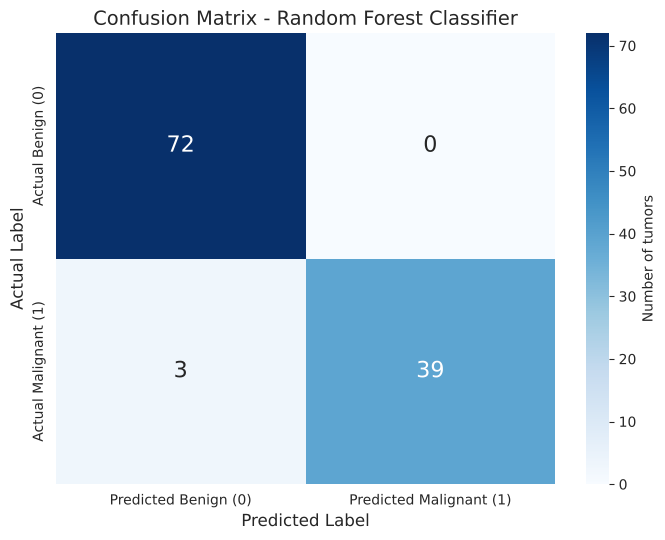

In [39]:
# Confusion matrix as a heatmap
plt.figure(figsize=(7, 5.5))
sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues", annot_kws={"size": 16}, cbar_kws={"label": "Number of tumors"})
plt.title("Confusion Matrix - Random Forest Classifier", fontsize=14)
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("Actual Label", fontsize=12)
plt.tight_layout()
plt.show()

In [40]:
# Break the confusion matrix into its four parts
tn, fp, fn, tp = cm.ravel()
print(f"True Negatives  (benign correctly predicted as benign)        : {tn}")
print(f"False Positives (benign wrongly predicted as malignant)       : {fp}")
print(f"False Negatives (malignant wrongly predicted as benign)       : {fn}")
print(f"True Positives  (malignant correctly predicted as malignant)  : {tp}")

True Negatives  (benign correctly predicted as benign)        : 72
False Positives (benign wrongly predicted as malignant)       : 0
False Negatives (malignant wrongly predicted as benign)       : 3
True Positives  (malignant correctly predicted as malignant)  : 39


In [41]:
# Classification report
print(classification_report(y_test, y_pred, target_names=["Benign (0)", "Malignant (1)"]))

               precision    recall  f1-score   support

   Benign (0)       0.96      1.00      0.98        72
Malignant (1)       1.00      0.93      0.96        42

     accuracy                           0.97       114
    macro avg       0.98      0.96      0.97       114
 weighted avg       0.97      0.97      0.97       114



**What the evaluation results mean in simple language:**

- **Accuracy = 97.37%.** Out of **114** tumors the model had never seen, it classified **111** correctly and **3** incorrectly.
- **Confusion matrix:** the model correctly identified **72 benign** tumors and **39 malignant** tumors. It made **0** false-alarm mistake(s) (benign predicted as malignant) and **3** dangerous mistake(s) (malignant predicted as benign).
- **Precision** answers: "when the model says *malignant*, how often is it right?" For malignant tumors it is **1.00**. 
- **Recall** answers: "of all truly malignant tumors, how many did the model find?" For malignant tumors it is **0.93**. In medicine recall for the malignant class is especially important, because a missed cancer is more serious than a false alarm.
- **F1-score** combines precision and recall into one number: **0.96** for malignant and **0.98** for benign.

## 16. Results and Observations

To understand *why* the model works, we look at which features the Random Forest relied on most (`feature_importances_`), and then print a short summary of the results.

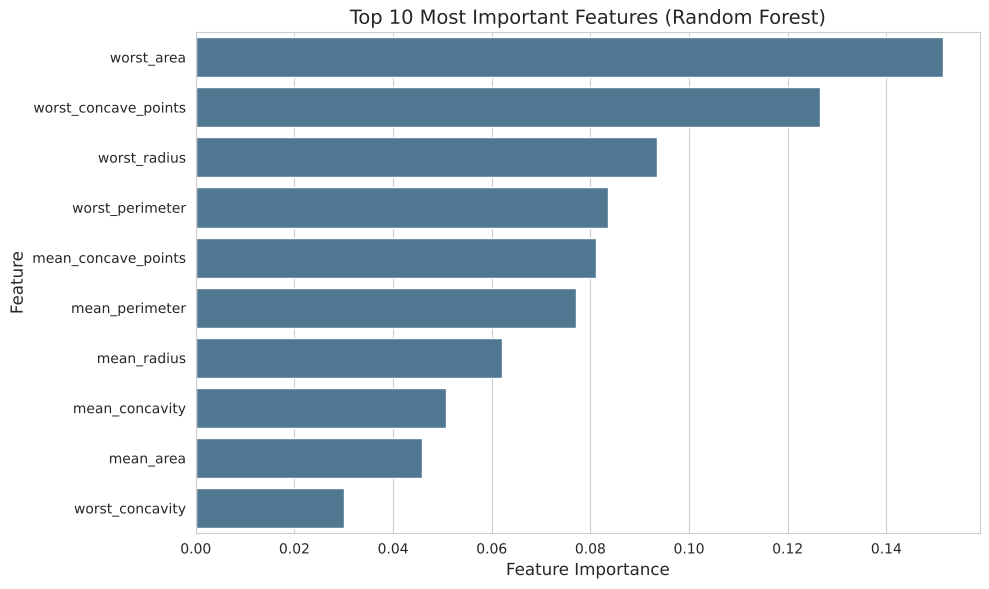

In [42]:
# Most important features according to the Random Forest
importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False)
top_importances = importances.head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_importances.values, y=top_importances.index, color="#457b9d")
plt.title("Top 10 Most Important Features (Random Forest)", fontsize=14)
plt.xlabel("Feature Importance", fontsize=12)
plt.ylabel("Feature", fontsize=12)
plt.tight_layout()
plt.show()

In [43]:
# Summary of results (all numbers come from the code above)
n_correct = int((y_test.values == y_pred).sum())
n_total = len(y_test)

print("=" * 55)
print("RESULTS SUMMARY")
print("=" * 55)
print("Algorithm               : RandomForestClassifier (random_state=42)")
print("Training samples        :", len(y_train))
print("Testing samples         :", n_total)
print("Correct predictions     :", n_correct)
print("Incorrect predictions   :", n_total - n_correct)
print(f"Accuracy on test data   : {accuracy * 100:.2f}%")
print("Most important features :", ", ".join(importances.head(3).index))
print("=" * 55)

RESULTS SUMMARY
Algorithm               : RandomForestClassifier (random_state=42)
Training samples        : 455
Testing samples         : 114
Correct predictions     : 111
Incorrect predictions   : 3
Accuracy on test data   : 97.37%
Most important features : worst_area, worst_concave_points, worst_radius


**Observations:**

1. **The classes are fairly balanced:** 62.74% benign and 37.26% malignant, so accuracy is a meaningful metric here (we still check precision, recall and F1).
2. **Malignant tumors are larger and more irregular.** Their radius, perimeter, area, concavity and concave points are noticeably higher than for benign tumors.
3. **Many features are strongly correlated** (for example radius, perimeter and area), so several columns carry similar information.
4. **Random Forest's most important features** were `worst_area`, `worst_concave_points` and `worst_radius`. These are mostly size and concavity measurements - the same kind of features that EDA and correlation analysis showed to be most different between malignant and benign tumors.
5. **The model reached 97.37% accuracy** on the unseen test set, with a very small number of errors.
6. **No data leakage:** the data was split first, and the scaler was fitted on the training set only.

## 17. Final Conclusion

**What the project accomplishes:** This project builds a machine learning model that classifies tumors as malignant (M) or benign (B) from numerical tumor measurements.

**Preprocessing performed:** The `id` column and the empty `Unnamed: 32` column were removed. Missing values were checked (none remained after removing the empty column) and duplicate rows were checked (none found). The `diagnosis` labels were converted to numbers (M = 1, B = 0), the data was split 80/20 with `random_state=42` and stratification, and `StandardScaler` was fitted on the training data only and then applied to the test data.

**What EDA revealed:** The dataset contains 357 benign and 212 malignant cases. Malignant tumors have clearly higher values for size and concavity features (radius, perimeter, area, concavity, concave points). Several features are strongly correlated with each other, and a few (such as fractal dimension) differ very little between the two groups.

**Algorithm implemented:** `RandomForestClassifier` from `sklearn.ensemble` with `random_state=42`.

**Actual model accuracy:** After running the notebook, the model achieved **97.37% accuracy** on the test set (111 of 114 correct). The confusion matrix shows 0 false positive(s) and 3 false negative(s); the malignant class has precision 1.00 and recall 0.93.

**Can the model distinguish malignant from benign tumors?** Yes. On this dataset and this train-test split the model separates malignant and benign tumors very well, and it agrees with the patterns found in the EDA and correlation analysis.

**Limitations:** This is an **educational machine learning project**. It uses a single dataset and a single train-test split, so the result may change slightly with other splits or data. It is **not a clinically validated diagnostic system** and must never be used to make real medical decisions.